In [1]:
#Importing the libraries

import pandas as pd    #For Data Collection and for data cleaning
from sklearn.model_selection import train_test_split #80% for training and 20% for testing
from sklearn.ensemble import RandomForestRegressor   #Model used for fitting training variables and predictions are made on independent testing variable
from sklearn.metrics import r2_score  #Model Evaluation
import plotly.express as px   #Advanced Data Visualisation
import matplotlib.pyplot as plt 

Data Loading

In [2]:
df = pd.read_csv(r"C:\Users\Damya\Downloads\diamond price prediction dataset.csv")

In [3]:
df

,Unnamed: 0,carat,cut,color,clarity,depth,table,x,y,z,price
0,1,0.30,Ideal,E,SI1,62.1,58.0,4.27,4.29,2.66,499
1,2,0.33,Premium,G,IF,60.8,58.0,4.42,4.46,2.70,984
2,3,0.90,Very Good,E,VVS2,62.2,60.0,6.04,6.12,3.78,6289
3,4,0.42,Ideal,F,VS1,61.6,56.0,4.82,4.80,2.96,1082
4,5,0.31,Ideal,F,VVS1,60.4,59.0,4.35,4.43,2.65,779
...,...,...,...,...,...,...,...,...,...,...,...
26962,26963,1.11,Premium,G,SI1,62.3,58.0,6.61,6.52,4.09,5408
26963,26964,0.33,Ideal,H,IF,61.9,55.0,4.44,4.42,2.74,1114
26964,26965,0.51,Premium,E,VS2,61.7,58.0,5.12,5.15,3.17,1656
26965,26966,0.27,Very Good,F,VVS2,61.8,56.0,4.19,4.20,2.60,682


In [4]:
#Dropping the unwanted column(s).

In [5]:
df.columns

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x',
       'y', 'z', 'price'],
      dtype='str')

In [6]:
df = df.drop(columns = ['Unnamed: 0'])

In [7]:
df

,carat,cut,color,clarity,depth,table,x,y,z,price
0,0.30,Ideal,E,SI1,62.1,58.0,4.27,4.29,2.66,499
1,0.33,Premium,G,IF,60.8,58.0,4.42,4.46,2.70,984
2,0.90,Very Good,E,VVS2,62.2,60.0,6.04,6.12,3.78,6289
3,0.42,Ideal,F,VS1,61.6,56.0,4.82,4.80,2.96,1082
4,0.31,Ideal,F,VVS1,60.4,59.0,4.35,4.43,2.65,779
...,...,...,...,...,...,...,...,...,...,...
26962,1.11,Premium,G,SI1,62.3,58.0,6.61,6.52,4.09,5408
26963,0.33,Ideal,H,IF,61.9,55.0,4.44,4.42,2.74,1114
26964,0.51,Premium,E,VS2,61.7,58.0,5.12,5.15,3.17,1656
26965,0.27,Very Good,F,VVS2,61.8,56.0,4.19,4.20,2.60,682


In [8]:
df.head()

,carat,cut,color,clarity,depth,table,x,y,z,price
0,0.30,Ideal,E,SI1,62.1,58.0,4.27,4.29,2.66,499
1,0.33,Premium,G,IF,60.8,58.0,4.42,4.46,2.70,984
2,0.90,Very Good,E,VVS2,62.2,60.0,6.04,6.12,3.78,6289
3,0.42,Ideal,F,VS1,61.6,56.0,4.82,4.80,2.96,1082
4,0.31,Ideal,F,VVS1,60.4,59.0,4.35,4.43,2.65,779


In [9]:
df.tail()

,carat,cut,color,clarity,depth,table,x,y,z,price
26962,1.11,Premium,G,SI1,62.3,58.0,6.61,6.52,4.09,5408
26963,0.33,Ideal,H,IF,61.9,55.0,4.44,4.42,2.74,1114
26964,0.51,Premium,E,VS2,61.7,58.0,5.12,5.15,3.17,1656
26965,0.27,Very Good,F,VVS2,61.8,56.0,4.19,4.20,2.60,682
26966,1.25,Premium,J,SI1,62.0,58.0,6.90,6.88,4.27,5166


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26967 entries, 0 to 26966
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    26967 non-null  float64
 1   cut      26967 non-null  str    
 2   color    26967 non-null  str    
 3   clarity  26967 non-null  str    
 4   depth    26270 non-null  float64
 5   table    26967 non-null  float64
 6   x        26967 non-null  float64
 7   y        26967 non-null  float64
 8   z        26967 non-null  float64
 9   price    26967 non-null  int64  
dtypes: float64(6), int64(1), str(3)
memory usage: 2.3 MB


In [11]:
df.describe()

,carat,depth,table,x,y,z,price
count,26967.000000,26270.000000,26967.000000,26967.000000,26967.000000,26967.000000,26967.000000
mean,0.798375,61.745147,57.456080,5.729854,5.733569,3.538057,3939.518115
std,0.477745,1.412860,2.232068,1.128516,1.166058,0.720624,4024.864666
min,0.200000,50.800000,49.000000,0.000000,0.000000,0.000000,326.000000
25%,0.400000,61.000000,56.000000,4.710000,4.710000,2.900000,945.000000
50%,0.700000,61.800000,57.000000,5.690000,5.710000,3.520000,2375.000000
75%,1.050000,62.500000,59.000000,6.550000,6.540000,4.040000,5360.000000
max,4.500000,73.600000,79.000000,10.230000,58.900000,31.800000,18818.000000


In [22]:
corr = df.corr(numeric_only = True)

In [23]:
corr

,carat,depth,table,x,y,z,price
carat,1.000000,0.034895,0.181685,0.976368,0.941071,0.940640,0.922416
depth,0.034895,1.000000,-0.293958,-0.018431,-0.024399,0.097413,-0.002519
table,0.181685,-0.293958,1.000000,0.196206,0.182346,0.148944,0.126942
x,0.976368,-0.018431,0.196206,1.000000,0.962715,0.956606,0.886247
y,0.941071,-0.024399,0.182346,0.962715,1.000000,0.928923,0.856243
z,0.940640,0.097413,0.148944,0.956606,0.928923,1.000000,0.850536
price,0.922416,-0.002519,0.126942,0.886247,0.856243,0.850536,1.000000


In [24]:
import seaborn as sns

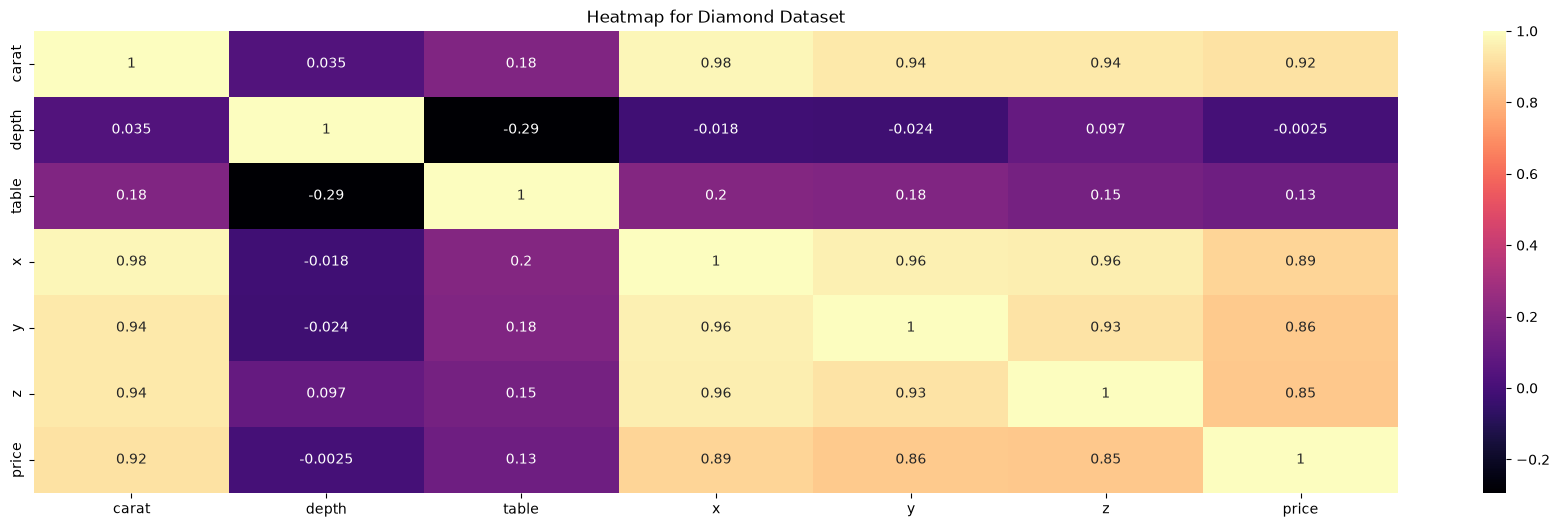

In [25]:
plt.figure(figsize = (22,6))
sns.heatmap(corr, annot = True, cmap = 'magma')
plt.title('Heatmap for Diamond Dataset')
plt.show()

In [17]:
df.isnull().sum()

carat        0
cut          0
color        0
clarity      0
depth      697
table        0
x            0
y            0
z            0
price        0
dtype: int64

In [18]:
#Filling the null values in data

df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z',
       'price'],
      dtype='str')

In [19]:
df['depth'] = df['depth'].fillna(df['depth'].median())

In [20]:
df

,carat,cut,color,clarity,depth,table,x,y,z,price
0,0.30,Ideal,E,SI1,62.1,58.0,4.27,4.29,2.66,499
1,0.33,Premium,G,IF,60.8,58.0,4.42,4.46,2.70,984
2,0.90,Very Good,E,VVS2,62.2,60.0,6.04,6.12,3.78,6289
3,0.42,Ideal,F,VS1,61.6,56.0,4.82,4.80,2.96,1082
4,0.31,Ideal,F,VVS1,60.4,59.0,4.35,4.43,2.65,779
...,...,...,...,...,...,...,...,...,...,...
26962,1.11,Premium,G,SI1,62.3,58.0,6.61,6.52,4.09,5408
26963,0.33,Ideal,H,IF,61.9,55.0,4.44,4.42,2.74,1114
26964,0.51,Premium,E,VS2,61.7,58.0,5.12,5.15,3.17,1656
26965,0.27,Very Good,F,VVS2,61.8,56.0,4.19,4.20,2.60,682


In [21]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
x          0
y          0
z          0
price      0
dtype: int64

Data Division Into X and y variables (X -> Input / Independent Variable and y -> Output / Dependent Variable)

In [26]:
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z',
       'price'],
      dtype='str')

In [36]:
X = df.drop(columns = ['price'])
y = df['price']

In [37]:
X

,carat,cut,color,clarity,depth,table,x,y,z
0,0.30,2,1,2,62.1,58.0,4.27,4.29,2.66
1,0.33,3,3,1,60.8,58.0,4.42,4.46,2.70
2,0.90,4,1,7,62.2,60.0,6.04,6.12,3.78
3,0.42,2,2,4,61.6,56.0,4.82,4.80,2.96
4,0.31,2,2,6,60.4,59.0,4.35,4.43,2.65
...,...,...,...,...,...,...,...,...,...
26962,1.11,3,3,2,62.3,58.0,6.61,6.52,4.09
26963,0.33,2,4,1,61.9,55.0,4.44,4.42,2.74
26964,0.51,3,1,5,61.7,58.0,5.12,5.15,3.17
26965,0.27,4,2,7,61.8,56.0,4.19,4.20,2.60


In [38]:
y

0         499
1         984
2        6289
3        1082
4         779
         ... 
26962    5408
26963    1114
26964    1656
26965     682
26966    5166
Name: price, Length: 26967, dtype: int64

Converting the text values into numeric values 

In [31]:
from sklearn.preprocessing import LabelEncoder

In [32]:
le = LabelEncoder()

In [33]:
for col in df.columns:
    if df[col].dtype == 'str':
        df[col] = le.fit_transform(df[col].astype('str'))

In [34]:
df

,carat,cut,color,clarity,depth,table,x,y,z,price
0,0.30,2,1,2,62.1,58.0,4.27,4.29,2.66,499
1,0.33,3,3,1,60.8,58.0,4.42,4.46,2.70,984
2,0.90,4,1,7,62.2,60.0,6.04,6.12,3.78,6289
3,0.42,2,2,4,61.6,56.0,4.82,4.80,2.96,1082
4,0.31,2,2,6,60.4,59.0,4.35,4.43,2.65,779
...,...,...,...,...,...,...,...,...,...,...
26962,1.11,3,3,2,62.3,58.0,6.61,6.52,4.09,5408
26963,0.33,2,4,1,61.9,55.0,4.44,4.42,2.74,1114
26964,0.51,3,1,5,61.7,58.0,5.12,5.15,3.17,1656
26965,0.27,4,2,7,61.8,56.0,4.19,4.20,2.60,682


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26967 entries, 0 to 26966
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    26967 non-null  float64
 1   cut      26967 non-null  int64  
 2   color    26967 non-null  int64  
 3   clarity  26967 non-null  int64  
 4   depth    26967 non-null  float64
 5   table    26967 non-null  float64
 6   x        26967 non-null  float64
 7   y        26967 non-null  float64
 8   z        26967 non-null  float64
 9   price    26967 non-null  int64  
dtypes: float64(6), int64(4)
memory usage: 2.1 MB


In [39]:
#Splitting the data into training & testing

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

In [41]:
X_train

,carat,cut,color,clarity,depth,table,x,y,z
3658,0.50,4,3,2,61.8,52.0,5.10,5.15,3.20
257,1.53,3,3,4,61.0,60.0,7.43,7.40,4.52
2202,1.00,4,0,2,61.3,54.0,6.37,6.39,3.91
12272,1.58,3,6,7,61.0,58.0,7.56,7.49,4.59
13022,0.72,2,2,5,61.8,56.0,5.72,5.74,3.54
...,...,...,...,...,...,...,...,...,...
21575,0.41,2,2,4,60.8,57.0,4.77,4.80,2.91
5390,0.33,4,4,4,59.7,59.0,4.52,4.53,2.70
860,0.39,2,3,6,61.8,56.0,4.66,4.70,2.90
15795,0.33,2,6,2,61.1,56.0,4.49,4.55,2.76


In [42]:
X_test

,carat,cut,color,clarity,depth,table,x,y,z
9922,1.10,4,2,2,60.5,60.0,6.65,6.67,4.03
25556,0.41,1,1,3,63.5,55.0,4.69,4.73,2.99
22421,0.25,3,4,6,59.8,59.0,4.07,4.09,2.44
18128,1.52,2,4,7,62.8,56.0,7.32,7.30,4.59
14105,0.42,2,0,7,62.1,55.0,4.78,4.81,2.98
...,...,...,...,...,...,...,...,...,...
10444,0.53,2,3,7,62.5,54.0,5.19,5.21,3.25
4256,1.26,4,4,2,62.5,56.0,6.88,6.93,4.31
13538,0.50,3,0,5,62.2,60.0,5.15,5.05,3.17
15461,0.71,4,2,5,59.5,58.0,5.82,5.87,3.48


In [43]:
y_train

3658      1153
257      14344
2202      5390
12272     7592
13022     3564
         ...  
21575     1007
5390       579
860        978
15795      403
23654      872
Name: price, Length: 21573, dtype: int64

In [44]:
y_test

9922      5667
25556      638
22421      450
18128    12764
14105     1326
         ...  
10444     1818
4256      7477
13538     1431
15461     2918
25686     5219
Name: price, Length: 5394, dtype: int64

Model Loading for fitting training variables and predictions made on independent testing variable

In [47]:
model = RandomForestRegressor(n_estimators = 100,random_st)

In [48]:
model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [49]:
p = model.predict(X_test)

In [50]:
p

array([5529.98,  635.96,  505.64, ..., 1851.91, 2856.97, 4929.87],
      shape=(5394,))

In [51]:
y_test

9922      5667
25556      638
22421      450
18128    12764
14105     1326
         ...  
10444     1818
4256      7477
13538     1431
15461     2918
25686     5219
Name: price, Length: 5394, dtype: int64

In [52]:
r2 = r2_score(y_test,p)

In [53]:
r2

0.9804631361014693

In [54]:
m1 = model.score(X_train,y_train)
m2 = model.score(X_test,y_test)

In [55]:
print('Training Score : ',m1*100,'%')
print('Testing Score : ',m2*100,'%')

Training Score :  99.70557052166158 %
Testing Score :  98.04631361014692 %


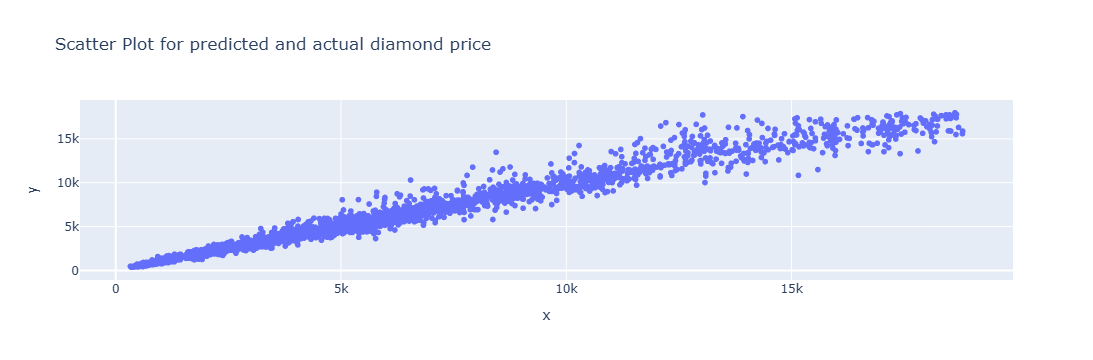

In [56]:
px.scatter(x = y_test, y  = p, title = 'Scatter Plot for predicted and actual diamond price').show()

In [57]:
fi = model.feature_importances_

In [58]:
fi

array([0.58647093, 0.00134893, 0.02842506, 0.06268032, 0.00349044,
       0.00259253, 0.0051837 , 0.30383701, 0.00597107])

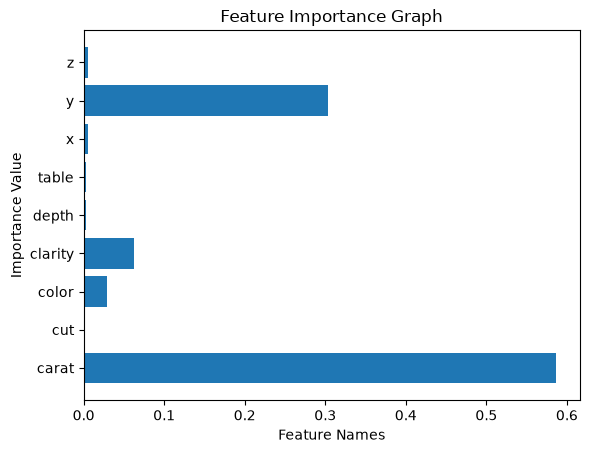

In [59]:
plt.barh(X.columns, fi)
plt.xlabel('Feature Names')
plt.ylabel('Importance Value')
plt.title('Feature Importance Graph')
plt.show()